# Missingness-only baseline

I want to see how well a model can predict the diagnosis using just the pattern of missing fields. I am starting with logistic regression so I can see how much information is in that pattern before adding the images.

[PAD-UFES-20 dataset paper](https://doi.org/10.1016/j.dib.2020.106221) ·
[scikit-learn logistic regression](https://scikit-learn.org/1.8/modules/linear_model.html#logistic-regression) ·
[patient-grouped cross-validation](https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
)

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from src.data import CLINICAL_FIELDS, DIAGNOSES, load_metadata, patient_folds

## Load and inspect the data

The CSV uses both empty cells and `UNK`. I count both as missing and keep those rows because the missing fields are what I want to study. The model gets a 1 for a missing field and a 0 for a recorded field.

In [2]:
data = load_metadata(root / "data" / "metadata.csv")
X = data[CLINICAL_FIELDS].isna().astype(int)
y = data["diagnostic"]

print("Images:", len(data))
print("Patients:", data["patient_id"].nunique())
print("Clinical fields:", X.shape[1])
print("Images with at least one missing field:", X.any(axis=1).sum())

class_counts = data.groupby("diagnostic").agg(
    images=("img_id", "size"),
    patients=("patient_id", "nunique"),
)
display(class_counts)
display(X.sum().sort_values(ascending=False).rename("missing images").to_frame())

Images: 2298
Patients: 1373
Clinical fields: 21
Images with at least one missing field: 1308


,images,patients
diagnostic,,
ACK,730,525
BCC,845,513
MEL,52,36
NEV,244,185
SCC,192,133
SEK,235,176


,missing images
background_father,913
background_mother,906
smoke,804
drink,804
pesticide,804
diameter_2,804
gender,804
skin_cancer_history,804
cancer_history,804
has_piped_water,804


## Train and evaluate by patient

I use five folds and keep all images from each patient together. Each model predicts the images in its held-out fold. The majority baseline always predicts whichever diagnosis was most common in the training fold.

In [3]:
folds = patient_folds(data)
predictions = data[["img_id", "patient_id", "diagnostic"]].copy()
predictions["fold"] = 0
predictions["majority_class"] = ""
predictions["missingness_only"] = ""

for fold, (train_rows, test_rows) in enumerate(folds, start=1):
    X_train = X.iloc[train_rows]
    X_test = X.iloc[test_rows]
    y_train = y.iloc[train_rows]
    y_test = y.iloc[test_rows]

    majority = DummyClassifier(strategy="most_frequent")
    majority.fit(X_train, y_train)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    predictions.loc[X_test.index, "fold"] = fold
    predictions.loc[X_test.index, "majority_class"] = majority.predict(X_test)
    predictions.loc[X_test.index, "missingness_only"] = model.predict(X_test)

    print(f"Fold {fold}: {len(y_train)} train, {len(y_test)} held out, "
          f"{y_test.eq('MEL').sum()} held-out melanoma images")

Fold 1: 1838 train, 460 held out, 10 held-out melanoma images
Fold 2: 1838 train, 460 held out, 11 held-out melanoma images
Fold 3: 1839 train, 459 held out, 10 held-out melanoma images
Fold 4: 1838 train, 460 held out, 11 held-out melanoma images
Fold 5: 1839 train, 459 held out, 10 held-out melanoma images


## Compare the results

I report balanced accuracy and macro F1 because the classes are uneven. Balanced accuracy averages the recall across the six diagnoses. The confusion matrix shows how many images from each true class got each prediction.

In [4]:
scores = []
per_class = pd.DataFrame({"images": y.value_counts().reindex(DIAGNOSES)})

for name in ["majority_class", "missingness_only"]:
    predicted = predictions[name]
    scores.append({
        "model": name,
        "accuracy": accuracy_score(y, predicted),
        "balanced_accuracy": balanced_accuracy_score(y, predicted),
        "macro_f1": f1_score(y, predicted, average="macro"),
    })
    per_class[name + "_recall"] = recall_score(
        y, predicted, labels=DIAGNOSES, average=None
    )

metrics = pd.DataFrame(scores).set_index("model")
per_class.index.name = "diagnosis"

display(metrics.round(3))
display(per_class.round(3))

examples = predictions[["fold", "diagnostic", "missingness_only"]].head()
display(examples)

,accuracy,balanced_accuracy,macro_f1
model,,,
majority_class,0.368,0.167,0.090
missingness_only,0.562,0.269,0.219


,images,majority_class_recall,missingness_only_recall
diagnosis,,,
ACK,730,0.0,0.623
BCC,845,1.0,0.988
MEL,52,0.0,0.000
NEV,244,0.0,0.004
SCC,192,0.0,0.000
SEK,235,0.0,0.000


,fold,diagnostic,missingness_only
0,2,NEV,ACK
1,5,BCC,BCC
2,5,ACK,ACK
3,5,ACK,ACK
4,2,BCC,BCC


Saved the metrics and plot in results/ and held-out predictions in data/processed/.


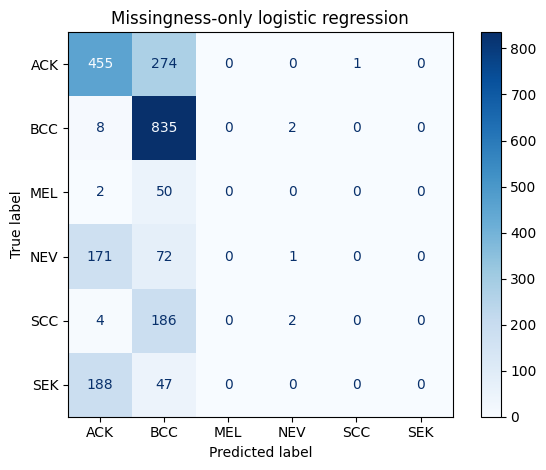

In [5]:
results_dir = root / "results"
results_dir.mkdir(exist_ok=True)
metrics.to_csv(results_dir / "missingness_metrics.csv")
per_class.to_csv(results_dir / "missingness_per_class.csv")

ConfusionMatrixDisplay.from_predictions(
    y, predictions["missingness_only"], labels=DIAGNOSES, cmap="Blues"
)
plt.title("Missingness-only logistic regression")
plt.tight_layout()
plt.savefig(results_dir / "missingness_confusion_matrix.png", dpi=180)
plt.show()

processed_dir = root / "data" / "processed"
processed_dir.mkdir(exist_ok=True)
predictions.to_csv(processed_dir / "missingness_predictions.csv", index=False)
print("Saved the metrics and plot in results/ and held-out predictions in data/processed/.")